# COMPLETE ACNE DATASET ANALYSIS

Analysed Dataset structure:
```
Models/
└── yolo/
    └── data/
        └── dataset_final_preprocessed_acne04_only/
            ├── train/
            │   ├── images/
            │   └── labels/
            ├── val/
            │   ├── images/
            │   └── labels/
            └── test/
                ├── images/
                └── labels/
```
Filename convention:
```
  levle0_1.jpg -> acne level 0
  levle1_15.jpg -> acne level 1
  levle2_42.jpg -> acne level 2
  levle3_133.jpg -> acne level 3
```

YOLO annotation format: class_id center_x center_y width height
Example: 0 0.346080 0.697049 0.010925 0.009838

In [36]:
# IMPORTS

from pathlib import Path
from collections import Counter
import re
import math
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [37]:
DATASET_DIR = Path(
    r"..\data\dataset_final_preprocessed_acne04_only"
)

print("Dataset:")
print(DATASET_DIR.resolve())

Dataset:
D:\studia\DermaAI\Models\yolo\data\dataset_final_preprocessed_acne04_only


In [38]:
possible_splits = [
    "train",
    "valid",
    "val",
    "validation",
    "test"
]


splits = []


for split_name in possible_splits:

    split_dir = DATASET_DIR / split_name

    images_dir = split_dir / "images"
    labels_dir = split_dir / "labels"

    if (
        images_dir.exists()
        or
        labels_dir.exists()
    ):

        splits.append(split_name)


print()
print("Detected dataset splits:")

if len(splits) == 0:

    print("NO SPLITS FOUND")

    print()
    print("Dataset contents:")
    
    for item in DATASET_DIR.iterdir():
        print("  ", item)

    raise FileNotFoundError(
        "No train/valid/test directories were found."
    )


for split in splits:

    print(f"- {split}")


Detected dataset splits:
- train
- valid
- test


### Functions 

In [39]:
def extract_acne_level(filename):
    """
    Extract acne level from filename.

    Examples:
        levle0_1.jpg   -> 0
        levle1_25.jpg  -> 1
        levle2_42.jpg  -> 2
        levle3_133.jpg -> 3
    """

    match = re.match(r"levle(\d+)_", filename.lower())

    if match:
        return int(match.group(1))

    return None

def get_image_files(images_dir):

    if not images_dir.exists():

        return []

    valid_extensions = {
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp",
        ".tif",
        ".tiff"
    }

    return sorted([
        file
        for file in images_dir.iterdir()
        if (file.is_file() and file.suffix.lower() in valid_extensions)
    ])


def read_yolo_labels(label_path):

    annotations = []

    if not label_path.exists():
        return annotations

    try:
        with open(label_path, "r", encoding="utf-8") as file:
            lines = file.readlines()

    except Exception:
        return annotations


    for line_number, line in enumerate(lines, start=1):
        line = line.strip()

        if not line:
            continue

        parts = line.split()

        if len(parts) != 5:

            annotations.append({
                "valid": False,
                "line": line_number,
                "raw": line
            })

            continue

        try:

            class_id = int(parts[0])
            cx = float(parts[1])
            cy = float(parts[2])
            width = float(parts[3])
            height = float(parts[4])

            annotations.append({
                "valid": True,
                "line": line_number,
                "class_id": class_id,
                "cx": cx,
                "cy": cy,
                "width": width,
                "height": height
            })


        except ValueError:

            annotations.append({
                "valid": False,
                "line": line_number,
                "raw": line
            })

    return annotations

### COLLECT IMAGE AND BOUNDING BOX DATA

In [40]:
image_records = []
bbox_records = []
issues = []

for split in splits:
    print()
    print("=" * 70)
    print(f"PROCESSING: {split.upper()}")
    print("=" * 70)

    images_dir = DATASET_DIR / split / "images"
    labels_dir = DATASET_DIR / split / "labels"
    image_files = get_image_files(images_dir)

    print(f"Images found: {len(image_files):,}")

    # IMAGE / LABEL MATCHING

    image_stems = {image.stem for image in image_files}

    if labels_dir.exists():
        label_files = list(labels_dir.glob("*.txt"))
    else:
        label_files = []

    label_stems = {label.stem for label in label_files}

    # Labels without images

    orphan_labels = label_stems - image_stems

    for stem in orphan_labels:
        issues.append({
            "type": "label_without_image",
            "split": split,
            "file": stem + ".txt"
        })

    # Images without labels

    missing_labels = image_stems - label_stems

    for stem in missing_labels:
        issues.append({
            "type": "image_without_label",
            "split": split,
            "file": stem
        })

    # PROCESS EACH IMAGE

    for image_path in image_files:
        image_name = image_path.name
        image_stem = image_path.stem

        # ACNE LEVEL

        level = extract_acne_level(image_name)

        # IMAGE DIMENSIONS

        try:
            with Image.open(image_path) as image:
                image_width, image_height = image.size

        except Exception as error:
            issues.append({
                "type": "corrupted_image",
                "split": split,
                "file": image_name,
                "details": str(error)
            })
            continue

        # LABEL FILE

        label_path = labels_dir / f"{image_stem}.txt"
        annotations = read_yolo_labels(label_path)

        valid_annotations = [
            annotation
            for annotation in annotations
            if annotation.get("valid", False)
        ]

        invalid_annotations = [
            annotation
            for annotation in annotations
            if not annotation.get("valid", False)
        ]

        # INVALID ANNOTATIONS

        for annotation in invalid_annotations:
            issues.append({
                "type": "invalid_annotation_format",
                "split": split,
                "file": label_path.name,
                "line": annotation["line"]
            })

        # IMAGE RECORD

        image_records.append({
            "split": split,
            "image": image_name,
            "level": level,
            "width_px": image_width,
            "height_px": image_height,
            "image_area_px": image_width * image_height,
            "lesion_count": len(valid_annotations),
            "label_exists": label_path.exists(),
            "invalid_annotations": len(invalid_annotations)
        })

        # PROCESS BOUNDING BOXES

        for bbox_id, annotation in enumerate(valid_annotations):
            class_id = annotation["class_id"]
            cx = annotation["cx"]
            cy = annotation["cy"]
            bbox_width = annotation["width"]
            bbox_height = annotation["height"]

            # CLASS VALIDATION

            if class_id != 0:
                issues.append({
                    "type": "unexpected_class",
                    "split": split,
                    "file": label_path.name,
                    "line": annotation["line"],
                    "value": class_id
                })

            # YOLO RANGE VALIDATION

            if not (0 <= cx <= 1):
                issues.append({
                    "type": "center_x_out_of_range",
                    "split": split,
                    "file": label_path.name,
                    "line": annotation["line"],
                    "value": cx
                })

            if not (0 <= cy <= 1):
                issues.append({
                    "type": "center_y_out_of_range",
                    "split": split,
                    "file": label_path.name,
                    "line": annotation["line"],
                    "value": cy
                })

            if not (0 < bbox_width <= 1):
                issues.append({
                    "type": "width_out_of_range",
                    "split": split,
                    "file": label_path.name,
                    "line": annotation["line"],
                    "value": bbox_width
                })

            if not (0 < bbox_height <= 1):
                issues.append({
                    "type": "height_out_of_range",
                    "split": split,
                    "file": label_path.name,
                    "line": annotation["line"],
                    "value": bbox_height
                })

            # ABSOLUTE BBOX

            bbox_width_px = bbox_width * image_width
            bbox_height_px = bbox_height * image_height
            bbox_area_px = bbox_width_px * bbox_height_px
            bbox_area_relative = bbox_width * bbox_height

            x1 = cx * image_width - bbox_width_px / 2
            y1 = cy * image_height - bbox_height_px / 2
            x2 = cx * image_width + bbox_width_px / 2
            y2 = cy * image_height + bbox_height_px / 2

            # BBOX OUTSIDE IMAGE

            if x1 < 0 or y1 < 0 or x2 > image_width or y2 > image_height:
                issues.append({
                    "type": "bbox_outside_image",
                    "split": split,
                    "file": label_path.name,
                    "line": annotation["line"]
                })

            # BBOX RECORD

            bbox_records.append({
                "split": split,
                "image": image_name,
                "level": level,
                "bbox_id": bbox_id,
                "class_id": class_id,
                "center_x": cx,
                "center_y": cy,
                "width_relative": bbox_width,
                "height_relative": bbox_height,
                "width_px": bbox_width_px,
                "height_px": bbox_height_px,
                "area_relative": bbox_area_relative,
                "area_px": bbox_area_px
            })



PROCESSING: TRAIN
Images found: 805

PROCESSING: VALID
Images found: 243

PROCESSING: TEST
Images found: 116


### CREATE DATAFRAMES

In [41]:
images_df = pd.DataFrame(image_records)
bboxes_df = pd.DataFrame(bbox_records)
issues_df = pd.DataFrame(issues)

### DATASET OVERVIEW

In [42]:
print(f"Total images: {len(images_df):,}")
print(f"Total annotated lesions: {len(bboxes_df):,}")
print(f"Total dataset issues: {len(issues_df):,}")
print(f"Average lesions per image: {images_df['lesion_count'].mean():.2f}")
print(f"Median lesions per image: {images_df['lesion_count'].median():.2f}")
print(f"Minimum lesions per image: {images_df['lesion_count'].min()}")
print(f"Maximum lesions per image: {images_df['lesion_count'].max()}")

Total images: 1,164
Total annotated lesions: 31,423
Total dataset issues: 107
Average lesions per image: 27.00
Median lesions per image: 19.00
Minimum lesions per image: 1
Maximum lesions per image: 434


### ACNE LEVEL DISTRIBUTION

In [43]:
level_distribution = (
    images_df
    .groupby("level")
    .size()
    .reindex([0, 1, 2, 3], fill_value=0)
    .reset_index(name="images")
)

level_distribution["percentage"] = level_distribution["images"] / len(images_df) * 100

display(level_distribution.style.format({
    "percentage": "{:.2f}%"
}))

,level,images,percentage
0,0,460,39.52%
1,1,557,47.85%
2,2,125,10.74%
3,3,22,1.89%


### DATASET SPLIT DISTRIBUTION

In [44]:
split_distribution = (
    images_df["split"]
    .value_counts()
    .reindex(["train", "valid", "test"], fill_value=0)
    .reset_index()
)

split_distribution.columns = [
    "split",
    "images"
]

split_distribution["percentage"] = split_distribution["images"] / len(images_df) * 100

display(split_distribution.style.format({
    "percentage": "{:.2f}%"
}))

,split,images,percentage
0,train,805,69.16%
1,valid,243,20.88%
2,test,116,9.97%


### ACNE LEVEL DISTRIBUTION BY SPLIT

In [45]:
split_level_counts = pd.crosstab(
    images_df["split"],
    images_df["level"]
)

split_level_counts = split_level_counts.reindex(
    index=["train", "valid", "test"],
    columns=[0, 1, 2, 3],
    fill_value=0
)

split_level_distribution = split_level_counts.astype(str)

for split in split_level_counts.index:
    total = split_level_counts.loc[split].sum()

    for level in [0, 1, 2, 3]:
        count = split_level_counts.loc[split, level]
        percentage = count / total * 100
        split_level_distribution.loc[split, level] = f"{count:,} ({percentage:.2f}%)"

display(split_level_distribution)

level,0,1,2,3
split,,,,
train,315 (39.13%),386 (47.95%),90 (11.18%),14 (1.74%)
valid,100 (41.15%),108 (44.44%),28 (11.52%),7 (2.88%)
test,45 (38.79%),63 (54.31%),7 (6.03%),1 (0.86%)


### LESION COUNT BINS

In [46]:
lesion_bins_edges = [-1, 0, 1, 5, 10, 20, 30, 50, 100, 200, np.inf]

lesion_bin_labels = [
    "0",
    "1",
    "2-5",
    "6-10",
    "11-20",
    "21-30",
    "31-50",
    "51-100",
    "101-200",
    "200+"
]

images_df["lesion_bin"] = pd.cut(
    images_df["lesion_count"],
    bins=lesion_bins_edges,
    labels=lesion_bin_labels
)

lesion_bins = (
    images_df["lesion_bin"]
    .value_counts(sort=False)
    .reset_index()
)

lesion_bins.columns = [
    "lesion_count_range",
    "images"
]

lesion_bins["percentage"] = lesion_bins["images"] / len(images_df) * 100

display(lesion_bins.style.format({
    "percentage": "{:.2f}%"
}))

,lesion_count_range,images,percentage
0,0,0,0.00%
1,1,8,0.69%
2,2-5,113,9.71%
3,6-10,175,15.03%
4,11-20,325,27.92%
5,21-30,209,17.96%
6,31-50,179,15.38%
7,51-100,130,11.17%
8,101-200,22,1.89%
9,200+,3,0.26%


### LESION COUNT BY ACNE LEVEL

In [47]:
lesion_count_by_level = (
    images_df
    .groupby("level")["lesion_count"]
    .agg(
        images="count",
        total_lesions="sum",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .reindex([0, 1, 2, 3])
)

display(lesion_count_by_level.style.format({
    "mean": "{:.2f}",
    "median": "{:.2f}"
}))

,images,total_lesions,mean,median,minimum,maximum
level,,,,,,
0,460,7549,16.41,12.00,1,109
1,557,15141,27.18,22.00,1,143
2,125,6343,50.74,44.00,1,174
3,22,2390,108.64,73.50,17,434


### BOUNDING BOX STATISTICS

In [48]:
if len(bboxes_df) > 0:
    bbox_statistics = pd.DataFrame({
        "mean": bboxes_df[
            [
                "width_relative",
                "height_relative",
                "area_relative"
            ]
        ].mean(),
        "median": bboxes_df[
            [
                "width_relative",
                "height_relative",
                "area_relative"
            ]
        ].median(),
        "minimum": bboxes_df[
            [
                "width_relative",
                "height_relative",
                "area_relative"
            ]
        ].min(),
        "maximum": bboxes_df[
            [
                "width_relative",
                "height_relative",
                "area_relative"
            ]
        ].max()
    })

    display(bbox_statistics.style.format("{:.6f}"))

,mean,median,minimum,maximum
width_relative,0.017227,0.013496,0.001221,1.000000
height_relative,0.016072,0.012153,0.001157,1.000000
area_relative,0.001648,0.000164,0.000001,1.000000


### LESION AREA DISTRIBUTION

In [49]:
if len(bboxes_df) > 0:
    area_edges = [
        0,
        0.0001,
        0.0005,
        0.001,
        0.0025,
        0.005,
        0.01,
        0.02,
        0.05,
        1
    ]

    area_labels = [
        "<0.01%",
        "0.01-0.05%",
        "0.05-0.1%",
        "0.1-0.25%",
        "0.25-0.5%",
        "0.5-1%",
        "1-2%",
        "2-5%",
        ">5%"
    ]

    bboxes_df["area_bin"] = pd.cut(
        bboxes_df["area_relative"],
        bins=area_edges,
        labels=area_labels,
        include_lowest=True
    )

    area_distribution = (
        bboxes_df["area_bin"]
        .value_counts(sort=False)
        .reset_index()
    )

    area_distribution.columns = [
        "relative_area",
        "lesions"
    ]

    area_distribution["percentage"] = area_distribution["lesions"] / len(bboxes_df) * 100

    display(area_distribution.style.format({
        "percentage": "{:.2f}%"
    }))

,relative_area,lesions,percentage
0,<0.01%,9267,29.49%
1,0.01-0.05%,17476,55.62%
2,0.05-0.1%,3018,9.60%
3,0.1-0.25%,1295,4.12%
4,0.25-0.5%,223,0.71%
5,0.5-1%,73,0.23%
6,1-2%,19,0.06%
7,2-5%,3,0.01%
8,>5%,49,0.16%


### DATASET VALIDATION

In [50]:
if len(issues_df) == 0:
    print("No structural or annotation issues detected.")
else:
    issue_summary = (
        issues_df["type"]
        .value_counts()
        .reset_index()
    )

    issue_summary.columns = [
        "issue_type",
        "count"
    ]

    display(issue_summary)

,issue_type,count
0,bbox_outside_image,107


### BASIC DATASET QUALITY CHECKS

In [51]:
zero_annotation_images = images_df[
    images_df["lesion_count"] == 0
]

images_without_labels = images_df[
    ~images_df["label_exists"]
]

unknown_level_images = images_df[
    images_df["level"].isna()
]

print(f"Images with zero annotations: {len(zero_annotation_images):,}")
print(f"Images without label files: {len(images_without_labels):,}")
print(f"Images with unknown acne level: {len(unknown_level_images):,}")

Images with zero annotations: 0
Images without label files: 0
Images with unknown acne level: 0


### PLOT - ACNE LEVEL DISTRIBUTION

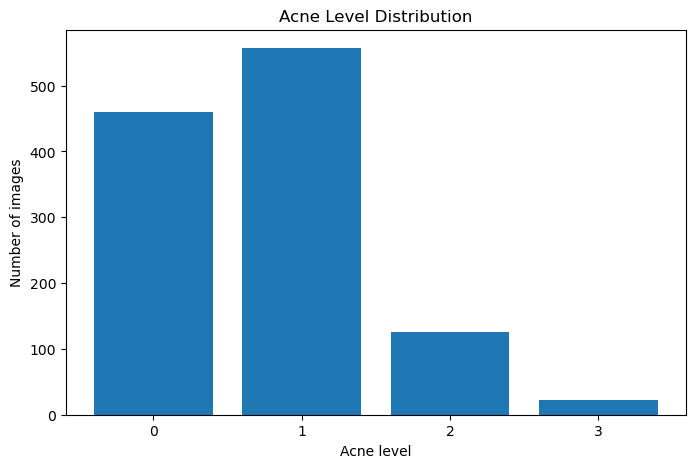

In [52]:
plt.figure(figsize=(8, 5))
plt.bar(
    level_distribution["level"].astype(str),
    level_distribution["images"]
)
plt.xlabel("Acne level")
plt.ylabel("Number of images")
plt.title("Acne Level Distribution")
plt.show()

### BOXPLOT - LESIONS BY LEVEL

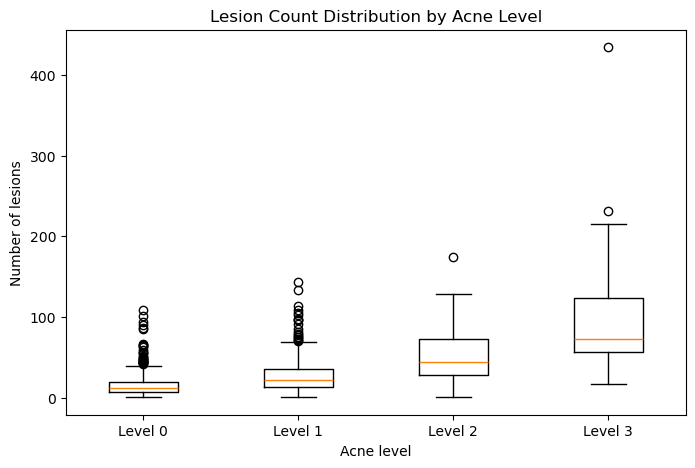

In [53]:
plt.figure(figsize=(8, 5))

boxplot_data = []
boxplot_labels = []

for level in [0, 1, 2, 3]:
    values = images_df[
        images_df["level"] == level
    ]["lesion_count"]

    if len(values) > 0:
        boxplot_data.append(values)
        boxplot_labels.append(f"Level {level}")

plt.boxplot(
    boxplot_data,
    tick_labels=boxplot_labels
)

plt.xlabel("Acne level")
plt.ylabel("Number of lesions")
plt.title("Lesion Count Distribution by Acne Level")
plt.show()

### SUMMARY

In [54]:
for level in [0, 1, 2, 3]:
    row = level_distribution[level_distribution["level"] == level]

    if len(row) > 0:
        count = int(row["images"].iloc[0])
        percentage = float(row["percentage"].iloc[0])
    else:
        count = 0
        percentage = 0

    print(f"Level {level}: {count:,} images ({percentage:.2f}%)")

print()
print(f"Total images: {len(images_df):,}")
print(f"Total lesions: {len(bboxes_df):,}")
print(f"Mean lesions/image: {images_df['lesion_count'].mean():.2f}")
print(f"Median lesions/image: {images_df['lesion_count'].median():.2f}")
print(f"Min lesions/image: {images_df['lesion_count'].min()}")
print(f"Max lesions/image: {images_df['lesion_count'].max()}")
print(f"Dataset issues: {len(issues_df):,}")

Level 0: 460 images (39.52%)
Level 1: 557 images (47.85%)
Level 2: 125 images (10.74%)
Level 3: 22 images (1.89%)

Total images: 1,164
Total lesions: 31,423
Mean lesions/image: 27.00
Median lesions/image: 19.00
Min lesions/image: 1
Max lesions/image: 434
Dataset issues: 107


In [55]:
# images_df
# One row = one image

# bboxes_df
# One row = one acne lesion / bounding box

# issues_df
# One row = one detected dataset problem

# Example:
display(images_df)
display(bboxes_df)
display(issues_df)

# ============================================================

,split,image,level,width_px,height_px,image_area_px,lesion_count,label_exists,invalid_annotations,lesion_bin
0,train,levle0_1.jpg,0,3112,3456,10755072,14,True,0,11-20
1,train,levle0_100.jpg,0,3112,3456,10755072,6,True,0,6-10
2,train,levle0_101.jpg,0,3112,3456,10755072,11,True,0,11-20
3,train,levle0_102.jpg,0,3112,3456,10755072,10,True,0,6-10
4,train,levle0_104.jpg,0,3112,3456,10755072,8,True,0,6-10
...,...,...,...,...,...,...,...,...,...,...
1159,test,levle2_38.jpg,2,3112,3456,10755072,25,True,0,21-30
1160,test,levle2_44.jpg,2,3112,3456,10755072,14,True,0,11-20
1161,test,levle2_46.jpg,2,4912,3264,16032768,16,True,0,11-20
1162,test,levle2_57.jpg,2,4912,3264,16032768,16,True,0,11-20


,split,image,level,bbox_id,class_id,center_x,center_y,width_relative,height_relative,width_px,height_px,area_relative,area_px,area_bin
0,train,levle0_1.jpg,0,0,0,0.346080,0.697049,0.010925,0.009838,33.998600,34.000128,0.000107,1155.956752,0.01-0.05%
1,train,levle0_1.jpg,0,1,0,0.186375,0.709201,0.022494,0.020255,70.001328,70.001280,0.000456,4900.182562,0.01-0.05%
2,train,levle0_1.jpg,0,2,0,0.265424,0.560185,0.010925,0.009838,33.998600,34.000128,0.000107,1155.956752,0.01-0.05%
3,train,levle0_1.jpg,0,3,0,0.231362,0.365451,0.014139,0.012731,44.000568,43.998336,0.000180,1935.951775,0.01-0.05%
4,train,levle0_1.jpg,0,4,0,0.528599,0.357350,0.016067,0.014468,50.000504,50.001408,0.000232,2500.095601,0.01-0.05%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31418,test,levle3_115.jpg,3,117,0,0.617288,0.613715,0.021851,0.019676,68.000312,68.000256,0.000430,4624.038624,0.01-0.05%
31419,test,levle3_115.jpg,3,118,0,0.643638,0.556134,0.023779,0.021412,74.000248,73.999872,0.000509,5476.008880,0.05-0.1%
31420,test,levle3_115.jpg,3,119,0,0.600257,0.657407,0.027635,0.024884,86.000120,85.999104,0.000688,7395.933264,0.05-0.1%
31421,test,levle3_115.jpg,3,120,0,0.601864,0.745370,0.025707,0.023148,80.000184,79.999488,0.000595,6399.973760,0.05-0.1%


,type,split,file,line
0,bbox_outside_image,train,levle0_101.txt,3
1,bbox_outside_image,train,levle0_221.txt,2
2,bbox_outside_image,train,levle0_33.txt,42
3,bbox_outside_image,train,levle0_364.txt,11
4,bbox_outside_image,train,levle0_70.txt,11
...,...,...,...,...
102,bbox_outside_image,test,levle1_606.txt,28
103,bbox_outside_image,test,levle2_112.txt,4
104,bbox_outside_image,test,levle2_112.txt,21
105,bbox_outside_image,test,levle2_123.txt,5


## bbox_outside_image analysis

In [56]:
original_issues = issues_df[
    issues_df["type"] == "bbox_outside_image"
].copy()

original_issues["image"] = original_issues["file"].str.replace(
    ".txt", ".jpg", regex=False
)

original_issues["bbox_id"] = original_issues["line"] - 1

outside_check = bboxes_df.copy()

outside_check["x1"] = (
    outside_check["center_x"]
    - outside_check["width_relative"] / 2
)
outside_check["y1"] = (
    outside_check["center_y"]
    - outside_check["height_relative"] / 2
)
outside_check["x2"] = (
    outside_check["center_x"]
    + outside_check["width_relative"] / 2
)
outside_check["y2"] = (
    outside_check["center_y"]
    + outside_check["height_relative"] / 2
)

outside_check["outside"] = (
    (outside_check["x1"] < 0) |
    (outside_check["y1"] < 0) |
    (outside_check["x2"] > 1) |
    (outside_check["y2"] > 1)
)

print("=" * 70)
print("OUTSIDE BBOX DATASETS")
print("=" * 70)
print(f"Original outside issues: {len(original_issues):,}")
print(f"Detected outside bboxes: {outside_check['outside'].sum():,}")



OUTSIDE BBOX DATASETS
Original outside issues: 107
Detected outside bboxes: 107


In [57]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image

def visualize_random_outside_bbox(
    original_issues: pd.DataFrame,
    outside_check: pd.DataFrame,
    dataset_dir: Path | str
) -> pd.DataFrame:

    dataset_dir = Path(dataset_dir)
    
    random_issue = original_issues.sample(1).iloc[0]
    split = random_issue["split"]
    image_name = random_issue["image"]

    image_path = dataset_dir / split / "images" / image_name
    image = Image.open(image_path).convert("RGB")
    img_width, img_height = image.size

    image_bboxes = outside_check[
        (outside_check["split"] == split) &
        (outside_check["image"] == image_name)
    ].copy()

    problematic_bboxes = image_bboxes[image_bboxes["outside"]].copy()
    problematic_ids = problematic_bboxes["bbox_id"].tolist()
    problematic_count = len(problematic_ids)

    print("=" * 70)
    print("RANDOM BBOX OUTSIDE IMAGE EXAMPLE")
    print("=" * 70)
    print(f"Split:               {split}")
    print(f"Image:               {image_name}")
    print(f"Image size:          {img_width} × {img_height}")
    print(f"Total boxes:         {len(image_bboxes)}")
    print(f"Problematic boxes:   {problematic_count}")
    print(f"Problematic bbox IDs: {problematic_ids}")
    print()

    image_bboxes["x1_px"] = image_bboxes["x1"] * img_width
    image_bboxes["y1_px"] = image_bboxes["y1"] * img_height
    image_bboxes["x2_px"] = image_bboxes["x2"] * img_width
    image_bboxes["y2_px"] = image_bboxes["y2"] * img_height

    image_bboxes["status"] = np.where(
        image_bboxes["outside"],
        "OUTSIDE",
        "OK"
    )

    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(image)

    for _, bbox in image_bboxes.iterrows():
        x1 = bbox["x1_px"]
        y1 = bbox["y1_px"]
        x2 = bbox["x2_px"]
        y2 = bbox["y2_px"]
        width = x2 - x1
        height = y2 - y1

        if bbox["outside"]:
            linewidth = 3
            edgecolor = "red"
        else:
            linewidth = 1
            edgecolor = "limegreen"

        rect = Rectangle(
            (x1, y1),
            width,
            height,
            fill=False,
            linewidth=linewidth,
            edgecolor=edgecolor
        )
        ax.add_patch(rect)

        ax.text(
            x1,
            y1,
            str(int(bbox["bbox_id"])),
            fontsize=9,
            fontweight="bold",
            color=edgecolor
        )

    ax.set_title(f"{image_name} | {split}")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

    bbox_table = image_bboxes[
        [
            "bbox_id",
            "class_id",
            "center_x",
            "center_y",
            "width_relative",
            "height_relative",
            "x1",
            "y1",
            "x2",
            "y2",
            "x1_px",
            "y1_px",
            "x2_px",
            "y2_px",
            "status"
        ]
    ].copy()

    bbox_table = bbox_table.rename(
        columns={
            "width_relative": "width",
            "height_relative": "height"
        }
    )

    numeric_columns = bbox_table.select_dtypes(include=np.number).columns
    bbox_table[numeric_columns] = bbox_table[numeric_columns].round(4)

    print("=" * 70)
    print("BOUNDING BOX COORDINATES")
    print("=" * 70)
    display(bbox_table)


    return bbox_table

RANDOM BBOX OUTSIDE IMAGE EXAMPLE
Split:               train
Image:               levle2_130.jpg
Image size:          3112 × 3456
Total boxes:         67
Problematic boxes:   49
Problematic bbox IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48]



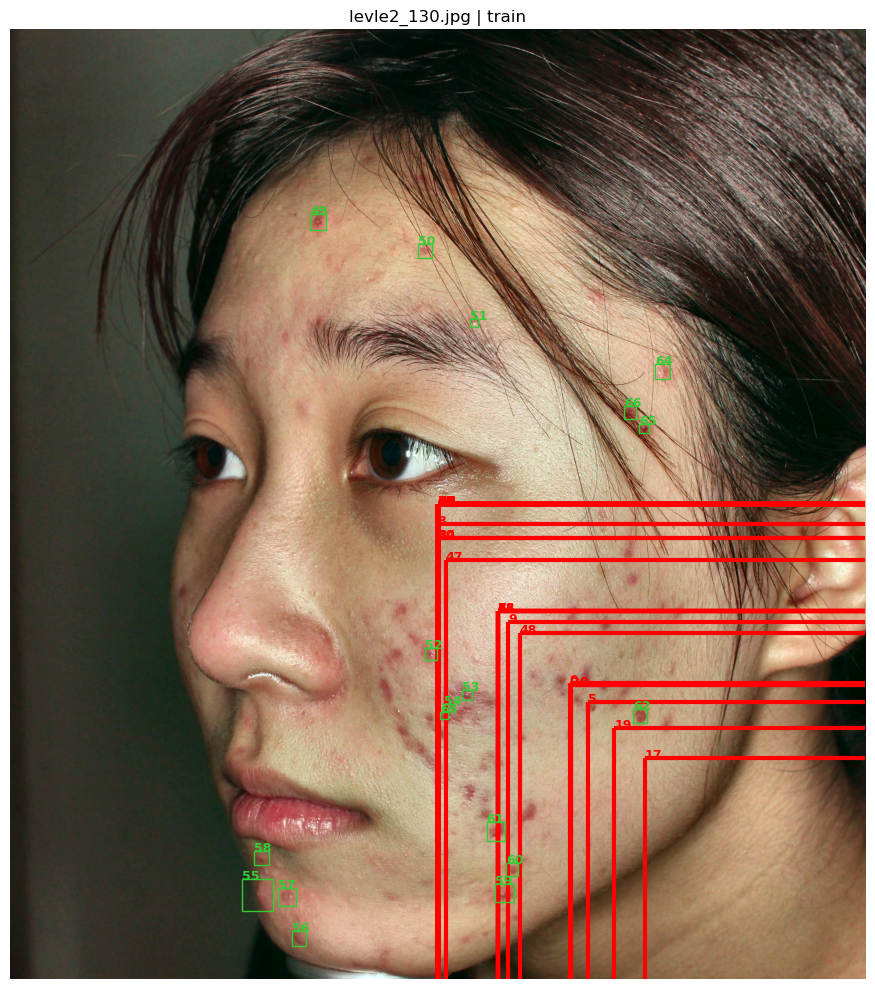

BOUNDING BOX COORDINATES


,bbox_id,class_id,center_x,center_y,width,height,x1,y1,x2,y2,x1_px,y1_px,x2_px,y2_px,status
16623,0,0,1.0000,1.0000,0.6915,0.6227,0.6542,0.6887,1.3458,1.3113,2035.9995,2380.0003,4188.0005,4531.9997,OUTSIDE
16624,1,0,1.0000,1.0000,0.8599,0.7743,0.5701,0.6128,1.4299,1.3872,1774.0003,2117.9992,4449.9997,4794.0008,OUTSIDE
16625,2,0,1.0000,1.0000,0.6877,0.6192,0.6562,0.6904,1.3438,1.3096,2041.9995,2385.9999,4182.0005,4526.0001,OUTSIDE
16626,3,0,1.0000,1.0000,0.8599,0.7743,0.5701,0.6128,1.4299,1.3872,1774.0003,2117.9992,4449.9997,4794.0008,OUTSIDE
16627,4,0,1.0000,1.0000,0.8599,0.7743,0.5701,0.6128,1.4299,1.3872,1774.0003,2117.9992,4449.9997,4794.0008,OUTSIDE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16685,62,0,0.7365,0.7228,0.0167,0.0150,0.7281,0.7153,0.7449,0.7303,2265.9997,2472.0008,2318.0012,2523.9997,OK
16686,63,0,0.5077,0.7225,0.0090,0.0081,0.5032,0.7185,0.5122,0.7266,1566.0004,2483.0012,1593.9991,2511.0017,OK
16687,64,0,0.7629,0.3602,0.0167,0.0150,0.7545,0.3527,0.7712,0.3678,2347.9978,1219.0003,2399.9993,1270.9993,OK
16688,65,0,0.7413,0.4201,0.0109,0.0098,0.7359,0.4152,0.7468,0.4251,2290.0010,1435.0003,2323.9996,1469.0004,OK


In [58]:
bbox_df = visualize_random_outside_bbox(
    original_issues=original_issues,
    outside_check=outside_check,
    dataset_dir=DATASET_DIR
)

RANDOM BBOX OUTSIDE IMAGE EXAMPLE
Split:               train
Image:               levle1_318.jpg
Image size:          3112 × 3456
Total boxes:         24
Problematic boxes:   1
Problematic bbox IDs: [22]



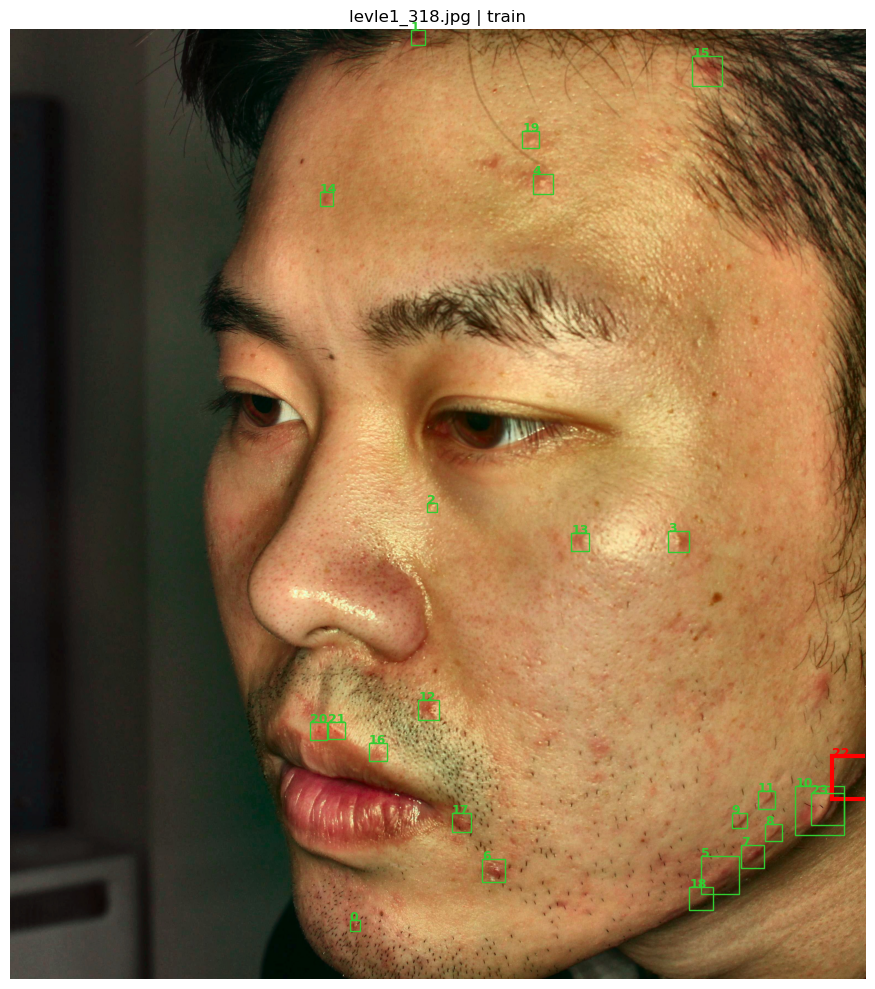

BOUNDING BOX COORDINATES


,bbox_id,class_id,center_x,center_y,width,height,x1,y1,x2,y2,x1_px,y1_px,x2_px,y2_px,status
8831,0,0,0.4033,0.9433,0.0129,0.0116,0.3969,0.9375,0.4097,0.9491,1235.0019,3240.0000,1275.0004,3279.9997,OK
8832,1,0,0.4769,0.0084,0.0167,0.0150,0.4685,0.0009,0.4852,0.0159,1458.0000,2.9998,1510.0015,54.9988,OK
8833,2,0,0.4933,0.5032,0.0109,0.0098,0.4878,0.4983,0.4987,0.5081,1518.0009,1722.0004,1551.9995,1756.0005,OK
8834,3,0,0.7818,0.5388,0.0244,0.0220,0.7696,0.5278,0.7940,0.5498,2394.9983,1823.9990,2470.9996,1899.9999,OK
8835,4,0,0.6228,0.1623,0.0231,0.0208,0.6112,0.1519,0.6343,0.1727,1902.0015,524.9992,1974.0007,596.9981,OK
8836,5,0,0.8300,0.8903,0.0443,0.0399,0.8078,0.8704,0.8522,0.9103,2514.0012,3008.0004,2651.9997,3146.0020,OK
8837,6,0,0.5656,0.8857,0.0264,0.0237,0.5524,0.8738,0.5787,0.8976,1719.0003,3019.9997,1801.0015,3102.0002,OK
8838,7,0,0.8679,0.8712,0.0270,0.0243,0.8544,0.8591,0.8814,0.8834,2659.0017,2968.9978,2743.0008,3052.9993,OK
8839,8,0,0.8927,0.8458,0.0199,0.0179,0.8827,0.8368,0.9026,0.8547,2747.0013,2891.9981,2809.0017,2953.9987,OK
8840,9,0,0.8525,0.8333,0.0174,0.0156,0.8438,0.8255,0.8612,0.8411,2625.9990,2852.9988,2679.9984,2906.9988,OK


In [60]:
bbox_df = visualize_random_outside_bbox(
    original_issues=original_issues,
    outside_check=outside_check,
    dataset_dir=DATASET_DIR
)

```md

VALID COORDINATE RANGES

YOLO coordinates:
  center_x : 0 ≤ center_x ≤ 1
  center_y : 0 ≤ center_y ≤ 1
  width    : 0 < width ≤ 1
  height   : 0 < height ≤ 1

Derived image boundaries:
  x1 : 0 ≤ x1 ≤ 1
  y1 : 0 ≤ y1 ≤ 1
  x2 : 0 ≤ x2 ≤ 1
  y2 : 0 ≤ y2 ≤ 1

Meaning:
  center_x = 0 → left edge of image
  center_x = 1 → right edge of image
  center_y = 0 → top edge of image
  center_y = 1 → bottom edge of image

A bbox is OUTSIDE if:
  x1 < 0 OR y1 < 0 OR x2 > 1 OR y2 > 1
```